# 04 · Churn prediction

**Question:** of the customers who bought in the last 6 months, which ones will **not** buy in the next 6 months?

This turns the "At risk" snapshot from `02` into a forecast that a retention team can act on: a ranked list of customers to contact.

**Design decisions:**
- **Population at a cutoff date:** customers with at least one purchase in the 180 days up to the cutoff.
- **Label:** `churned` = 1 if the customer makes no purchase in the 180 days after the cutoff. The 6-month window was chosen to leave more history for training. Its cost is measured in section 1.
- **No look-ahead.** Features are built with `split_purchases(lines, as_of=cutoff)` (`src/churn.py`), so a cancellation made after the cutoff cannot change them. The label applies only the cancellations made by the end of its window.
- **Validation over time:**
  - The models are trained on seven monthly cutoffs (June–December 2010) and tested once on 1 June 2011.
  - Every training label window ends before the test cutoff.
  - Within training, model comparison uses cross-validation grouped by customer, because the same customer appears at several cutoffs.
- **Metrics:** ROC-AUC and PR-AUC (churn is the positive class), the Brier score and calibration. Accuracy is not used.

In [1]:
import sys
from datetime import date, timedelta
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from statsmodels.stats.proportion import proportion_confint
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from src.churn import FEATURES, HORIZON_DAYS, LOOKBACK_DAYS, churn_dataset, churn_features
from src.cleaning import split_purchases
from src.config import CHURN_SCORES, LINES, RANDOM_STATE, SEGMENTS
from src.plotting import INK, INK_SECONDARY, NEUTRAL, SEGMENT_COLORS, SEGMENT_ORDER, save_fig, set_style

set_style()
pl.Config.set_tbl_cols(-1)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_rows(25)
lines = pl.read_parquet(LINES)

DATA_END = lines["invoice_date"].max().date()
TRAIN_CUTOFFS = [date(2010, month, 1) for month in range(6, 13)]
TEST_CUTOFF = date(2011, 6, 1)
LABELLED_CUTOFFS = TRAIN_CUTOFFS + [date(2011, month, 1) for month in range(1, 7)]  # label window fully observed
SCORE_CUTOFF = date(2011, 12, 1)  # last 1st-of-month cutoff, like the training cutoffs; the future is unknown

assert max(TRAIN_CUTOFFS) + timedelta(days=HORIZON_DAYS) <= TEST_CUTOFF, "a training label would overlap the test period"
assert TEST_CUTOFF + timedelta(days=HORIZON_DAYS) <= DATA_END, "the test label window must be fully observed"
assert min(TRAIN_CUTOFFS) - timedelta(days=LOOKBACK_DAYS) >= lines["invoice_date"].min().date()

datasets = {cutoff: churn_dataset(lines, cutoff) for cutoff in LABELLED_CUTOFFS}
train = pl.concat([datasets[c] for c in TRAIN_CUTOFFS])
test = datasets[TEST_CUTOFF]
print(f"Train: {train.height:,} rows ({train['customer_id'].n_unique():,} customers, {len(TRAIN_CUTOFFS)} cutoffs) | "
      f"test: {test.height:,} customers at {TEST_CUTOFF}")

Train: 20,567 rows (4,216 customers, 7 cutoffs) | test: 2,649 customers at 2011-06-01


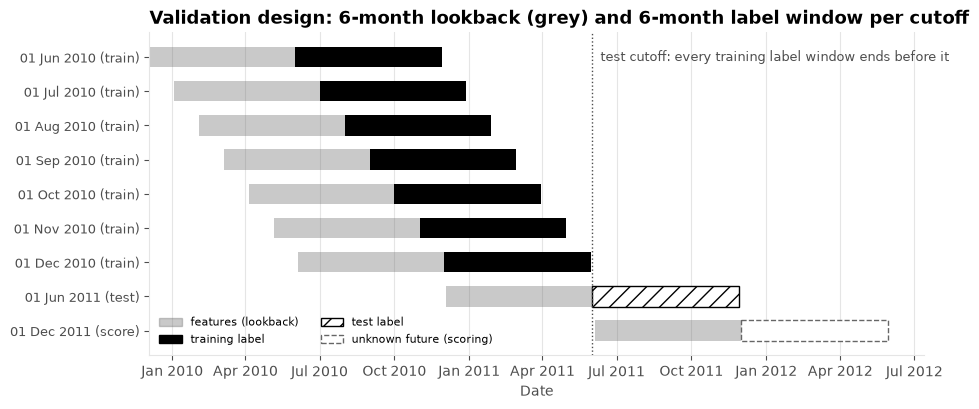

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.2))
rows = [(c, "train") for c in TRAIN_CUTOFFS] + [(TEST_CUTOFF, "test"), (SCORE_CUTOFF, "score")]
for y, (cutoff, role) in enumerate(rows):
    start = cutoff - timedelta(days=LOOKBACK_DAYS - 1)
    ax.barh(y, timedelta(days=LOOKBACK_DAYS), left=start, height=0.6, color=NEUTRAL, alpha=0.35)
    if role == "train":
        ax.barh(y, timedelta(days=HORIZON_DAYS), left=cutoff, height=0.6, color=INK)
    elif role == "test":
        ax.barh(y, timedelta(days=HORIZON_DAYS), left=cutoff, height=0.6, color="white", edgecolor=INK, hatch="//")
    else:
        ax.barh(y, timedelta(days=HORIZON_DAYS), left=cutoff, height=0.6, color="white", edgecolor=NEUTRAL, linestyle="--")
ax.axvline(TEST_CUTOFF, color=INK_SECONDARY, linestyle=":", linewidth=1)
ax.annotate("test cutoff: every training label window ends before it", (TEST_CUTOFF, 0),
            xytext=(6, 0), textcoords="offset points", fontsize=9, color=INK_SECONDARY, va="center")
ax.set_yticks(range(len(rows)), [f"{c:%d %b %Y} ({role})" for c, role in rows], fontsize=9)
ax.invert_yaxis()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_xlabel("Date")
ax.set_title("Validation design: 6-month lookback (grey) and 6-month label window per cutoff")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=NEUTRAL, alpha=0.35),
           plt.Rectangle((0, 0), 1, 1, color=INK),
           plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=INK, hatch="//"),
           plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=NEUTRAL, linestyle="--")]
ax.legend(handles, ["features (lookback)", "training label", "test label", "unknown future (scoring)"],
          loc="lower left", fontsize=8, ncols=2)
save_fig(fig, "04_validation_design")
plt.show()

## 1. The label

### 1.1 How common is churn, and does it depend on the season?

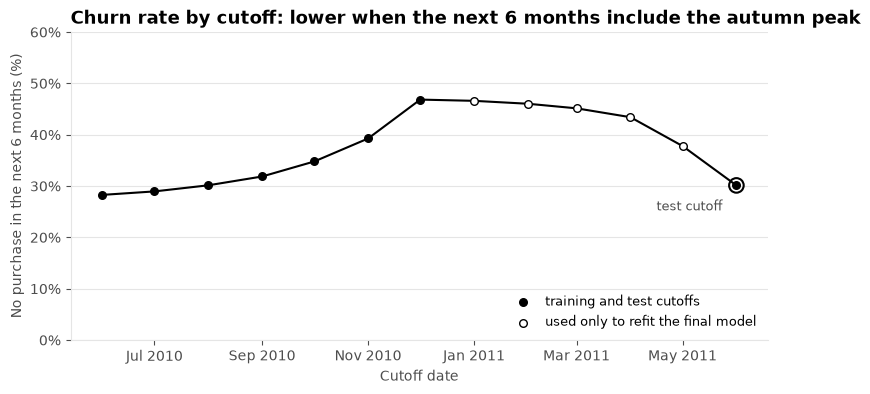

cutoff,customers,churn_rate,peak_days_ahead
date,i64,f64,i64
2010-06-01,2631,28.3,89
2010-07-01,2749,29.0,91
2010-08-01,2813,30.1,91
2010-09-01,2809,31.9,90
2010-10-01,2912,34.8,60
2010-11-01,3186,39.3,29
2010-12-01,3467,46.8,0
2011-01-01,3382,46.6,0
2011-02-01,3339,46.0,0


In [3]:
rates = pl.DataFrame([
    {"cutoff": c, "customers": d.height, "churn_rate": d["churned"].mean() * 100, "peak_days_ahead": d["peak_days_ahead"][0]}
    for c, d in datasets.items()
])

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rates["cutoff"], rates["churn_rate"], color=INK, linewidth=1.5)
refit_only = rates["cutoff"].is_in(TRAIN_CUTOFFS + [TEST_CUTOFF]).not_()
ax.scatter(rates.filter(~refit_only)["cutoff"], rates.filter(~refit_only)["churn_rate"], s=30, color=INK, zorder=3,
           label="training and test cutoffs")
ax.scatter(rates.filter(refit_only)["cutoff"], rates.filter(refit_only)["churn_rate"], s=30, facecolors="white",
           edgecolors=INK, zorder=3, label="used only to refit the final model")
ax.legend(loc="lower right", fontsize=9)
test_rate = rates.filter(pl.col("cutoff") == TEST_CUTOFF)["churn_rate"].item()
ax.scatter([TEST_CUTOFF], [test_rate], s=110, facecolors="none", edgecolors=INK, linewidths=1.5, zorder=3)
ax.annotate("test cutoff", (TEST_CUTOFF, test_rate), xytext=(-10, -18), textcoords="offset points", ha="right",
            color=INK_SECONDARY, fontsize=9)
ax.set_ylim(0, 60)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_xlabel("Cutoff date")
ax.set_ylabel("No purchase in the next 6 months (%)")
ax.set_title("Churn rate by cutoff: lower when the next 6 months include the autumn peak")
save_fig(fig, "04_churn_rate_by_cutoff")
plt.show()
rates.with_columns(pl.col("churn_rate").round(1))

`peak_days_ahead` is the number of September–November days in the label window. It is part of the calendar, so it is known at the cutoff, and it lets the model move its baseline with the season. It is the same for every customer at a given cutoff.

### 1.2 What does the 6-month window cost?

A 6-month window labels as churned some customers who are only slow, for example those who buy once a year (see `03`). For the training cutoffs, the data runs far enough to check how many "churned" customers buy again within the following 6 months (days 181–365 after the cutoff).

In [4]:
rows = []
for cutoff in TRAIN_CUTOFFS:
    churned = datasets[cutoff].filter(pl.col("churned") == 1)
    later = split_purchases(lines, as_of=cutoff + timedelta(days=365)).transactions.filter(
        pl.col("invoice_date").dt.date() > cutoff + timedelta(days=HORIZON_DAYS)
    ).select("customer_id").unique()
    rows.append({"cutoff": cutoff, "labelled_churned": churned.height,
                 "bought_again_days_181_365_pct": churned["customer_id"].is_in(later["customer_id"].implode()).mean() * 100})
pl.DataFrame(rows).with_columns(pl.col("bought_again_days_181_365_pct").round(1))

cutoff,labelled_churned,bought_again_days_181_365_pct
date,i64,f64
2010-06-01,744,23.9
2010-07-01,796,24.1
2010-08-01,848,25.1
2010-09-01,895,26.0
2010-10-01,1013,28.6
2010-11-01,1251,31.6
2010-12-01,1624,36.2


**Findings: the label**

- **Churn depends on the season.** About 3 in 10 customers stop buying when the next 6 months include the autumn peak, and nearly half when they don't. `peak_days_ahead` gives the model this calendar effect.
- **The cost of the 6-month window is large.** A quarter to a third of the customers labelled as churned buy again in the following 6 months, and more of them for the November and December cutoffs.
- In this project, "churn" therefore means **"no purchase in the next 6 months" (a lapse), not a permanent loss.** This is the documented price of choosing a 6-month window to keep more history for the features (`03` pointed to about 12–13 months).

## 2. Features

All features are computed from the 180-day lookback window, with what was known at the cutoff:

| Feature | Meaning |
|---|---|
| `recency_days` | days since the last purchase (0–179) |
| `orders` | distinct orders in the window |
| `avg_order_value` | product sales per order (£) |
| `products` | distinct products bought |
| `active_months` | calendar months with at least one purchase (1–7: the 180-day window can touch 7 calendar months, and the cutoff month counts as one even if the purchase was on its first day) |
| `cancelled_share` | value of cancellations not matched to a whole sale line by the cutoff / remaining sales |
| `is_uk` | customer based in the UK |
| `peak_days_ahead` | autumn-peak days in the label window (calendar) |

`split_purchases(as_of=cutoff)` removes each cancellation that matches a whole sale line together with that sale. So `cancelled_share` only counts the rest: partial returns, returns of older purchases and quantity or price mismatches. Total sales in the window is kept only to value the revenue at risk. It is not a feature, because on the log scale it is almost orders + average order value, and that collinearity makes the coefficients unreadable. Longer-history features, such as tenure or past seasonal buying, are left out. With only six months of history at the first training cutoff, they would mean different things at different cutoffs.

In [5]:
train.group_by("churned").agg(
    customers=pl.len(), **{f: pl.col(f).median() for f in FEATURES + ["sales"] if f not in ("is_uk", "peak_days_ahead")}
).sort("churned").with_columns(pl.col("sales", "avg_order_value").round(0))

churned,customers,recency_days,orders,avg_order_value,products,active_months,cancelled_share,sales
i8,u32,f64,f64,f64,f64,f64,f64,f64
0,13396,35.0,2.0,308.0,37.0,2.0,0.0,705.0
1,7171,64.0,1.0,245.0,20.0,1.0,0.0,318.0


## 3. Models

- **Heuristic baseline:** rank customers by recency alone (no model). The models have to beat this.
- **Logistic regression:** log1p for the skewed counts and amounts, then standardisation, all inside one sklearn `Pipeline`, so the transformations are fitted only on training folds.
- **Challenger:** gradient boosting (`HistGradientBoostingClassifier`, shallow trees, fixed regularised settings, no tuning).

**Criterion, fixed before running:** the challenger replaces the logistic regression only if its cross-validated PR-AUC is higher in all 5 folds and higher by at least 0.01 on average. Otherwise the simpler, more interpretable model is kept.

In [6]:
LOG_FEATURES = ["recency_days", "orders", "avg_order_value", "products"]
OTHER_FEATURES = [f for f in FEATURES if f not in LOG_FEATURES]


def make_logreg(features=FEATURES):
    preprocess = ColumnTransformer([
        ("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()),
         [f for f in LOG_FEATURES if f in features]),
        ("scale", StandardScaler(), [f for f in OTHER_FEATURES if f in features]),
    ])
    return make_pipeline(preprocess, LogisticRegression(max_iter=1000))


def make_challenger():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, l2_regularization=1.0,
                                          random_state=RANDOM_STATE)


X_train, y_train, groups = train.select(FEATURES), train["churned"].to_numpy(), train["customer_id"].to_numpy()
cv = GroupKFold(n_splits=5)
scores = {name: cross_validate(make(), X_train, y_train, groups=groups, cv=cv, scoring=["roc_auc", "average_precision"])
          for name, make in [("logistic_regression", make_logreg), ("gradient_boosting", make_challenger)]}

cv_table = pl.DataFrame({
    "fold": range(1, 6),
    **{f"{name}_roc_auc": s["test_roc_auc"] for name, s in scores.items()},
    **{f"{name}_pr_auc": s["test_average_precision"] for name, s in scores.items()},
}).with_columns(pl.exclude("fold").round(3))
print(cv_table)

gain = scores["gradient_boosting"]["test_average_precision"] - scores["logistic_regression"]["test_average_precision"]
replace = bool((gain > 0).all() and gain.mean() >= 0.01)
print(f"PR-AUC gain of the challenger per fold: {np.round(gain, 3)} -> replace logistic regression: {replace}")

shape: (5, 5)
┌──────┬─────────────────────────────┬───────────────────────────┬────────────────────────────┬──────────────────────────┐
│ fold ┆ logistic_regression_roc_auc ┆ gradient_boosting_roc_auc ┆ logistic_regression_pr_auc ┆ gradient_boosting_pr_auc │
│ ---  ┆ ---                         ┆ ---                       ┆ ---                        ┆ ---                      │
│ i64  ┆ f64                         ┆ f64                       ┆ f64                        ┆ f64                      │
╞══════╪═════════════════════════════╪═══════════════════════════╪════════════════════════════╪══════════════════════════╡
│ 1    ┆ 0.762                       ┆ 0.749                     ┆ 0.603                      ┆ 0.575                    │
│ 2    ┆ 0.755                       ┆ 0.76                      ┆ 0.578                      ┆ 0.585                    │
│ 3    ┆ 0.753                       ┆ 0.754                     ┆ 0.595                      ┆ 0.584                    │
│ 

In [7]:
# Pooled PR-AUC mixes cutoffs with churn rates from 28% to 47%; per cutoff it compares like for like with the test
out_of_fold = cross_val_predict(make_logreg(), X_train, y_train, groups=groups, cv=cv, method="predict_proba")[:, 1]
per_cutoff = []
for (cutoff,), part in train.with_columns(p=out_of_fold).group_by("cutoff"):
    per_cutoff.append({"cutoff": cutoff, "churn_rate": part["churned"].mean() * 100,
                       "pr_auc": average_precision_score(part["churned"], part["p"]),
                       "roc_auc": roc_auc_score(part["churned"], part["p"])})
pl.DataFrame(per_cutoff).sort("cutoff").with_columns(pl.exclude("cutoff").round(3))

cutoff,churn_rate,pr_auc,roc_auc
date,f64,f64,f64
2010-06-01,28.278,0.477,0.738
2010-07-01,28.956,0.494,0.74
2010-08-01,30.146,0.519,0.749
2010-09-01,31.862,0.525,0.732
2010-10-01,34.787,0.545,0.719
2010-11-01,39.266,0.598,0.732
2010-12-01,46.842,0.685,0.754


**Findings: model choice**

- **Logistic regression and gradient boosting perform about the same in cross-validation.** The challenger is worse in most folds, so it does not meet the criterion, and the simpler, interpretable model is kept.
- The pooled PR-AUC mixes cutoffs with very different churn rates. Per cutoff, it rises with the base rate, so the June 2010 cutoff is the like-for-like reference for the June 2011 test.
- **Caveat:** every fold contains all 7 cutoffs, so a flexible model could use `peak_days_ahead` as a cutoff identifier. This does not change the decision, because boosting lost anyway. For the same reason, the folds share calendar periods, so cross-validation here only compares the models: it is not a time-ordered estimate of future performance.

## 4. Test: 1 June 2011

The test cutoff is used once, after the model choice. Confidence intervals come from 1,000 bootstrap resamples of the test customers. The differences against the recency baseline are paired, on the same resamples.

In [8]:
model = make_logreg().fit(X_train, y_train)
challenger = make_challenger().fit(X_train, y_train)
y_test = test["churned"].to_numpy()
predictions = {
    "Logistic regression": model.predict_proba(test.select(FEATURES))[:, 1],
    "Gradient boosting": challenger.predict_proba(test.select(FEATURES))[:, 1],
    "Recency only": test["recency_days"].to_numpy().astype(float),
}

rng = np.random.default_rng(RANDOM_STATE)
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(1000)]


def metric_ci(metric, scores_):
    values = np.array([metric(y_test[i], scores_[i]) for i in boot_idx])
    return metric(y_test, scores_), *np.percentile(values, [2.5, 97.5])


rows = []
for name, p in predictions.items():
    for metric_name, metric in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score)]:
        value, low, high = metric_ci(metric, p)
        rows.append({"model": name, "metric": metric_name, "value": value, "ci_low": low, "ci_high": high})
    if name != "Recency only":
        value, low, high = metric_ci(brier_score_loss, p)
        rows.append({"model": name, "metric": "Brier score", "value": value, "ci_low": low, "ci_high": high})
print(f"Test churn rate: {y_test.mean():.1%} (PR-AUC of a random ranking)")
pl.DataFrame(rows).with_columns(pl.col("value", "ci_low", "ci_high").round(3))

Test churn rate: 30.1% (PR-AUC of a random ranking)


model,metric,value,ci_low,ci_high
str,str,f64,f64,f64
"""Logistic regression""","""ROC-AUC""",0.742,0.723,0.761
"""Logistic regression""","""PR-AUC""",0.496,0.46,0.533
"""Logistic regression""","""Brier score""",0.179,0.172,0.186
"""Gradient boosting""","""ROC-AUC""",0.738,0.721,0.757
"""Gradient boosting""","""PR-AUC""",0.49,0.455,0.526
"""Gradient boosting""","""Brier score""",0.181,0.173,0.188
"""Recency only""","""ROC-AUC""",0.663,0.639,0.685
"""Recency only""","""PR-AUC""",0.419,0.387,0.455


In [9]:
# Paired difference against the recency-only baseline
for metric_name, metric in [("ROC-AUC", roc_auc_score), ("PR-AUC", average_precision_score)]:
    diffs = np.array([metric(y_test[i], predictions["Logistic regression"][i]) - metric(y_test[i], predictions["Recency only"][i])
                      for i in boot_idx])
    point = metric(y_test, predictions["Logistic regression"]) - metric(y_test, predictions["Recency only"])
    print(f"{metric_name}: logistic regression - recency only = {point:.3f} "
          f"(95% CI {np.percentile(diffs, 2.5):.3f} to {np.percentile(diffs, 97.5):.3f})")

ROC-AUC: logistic regression - recency only = 0.079 (95% CI 0.057 to 0.100)


PR-AUC: logistic regression - recency only = 0.077 (95% CI 0.048 to 0.104)


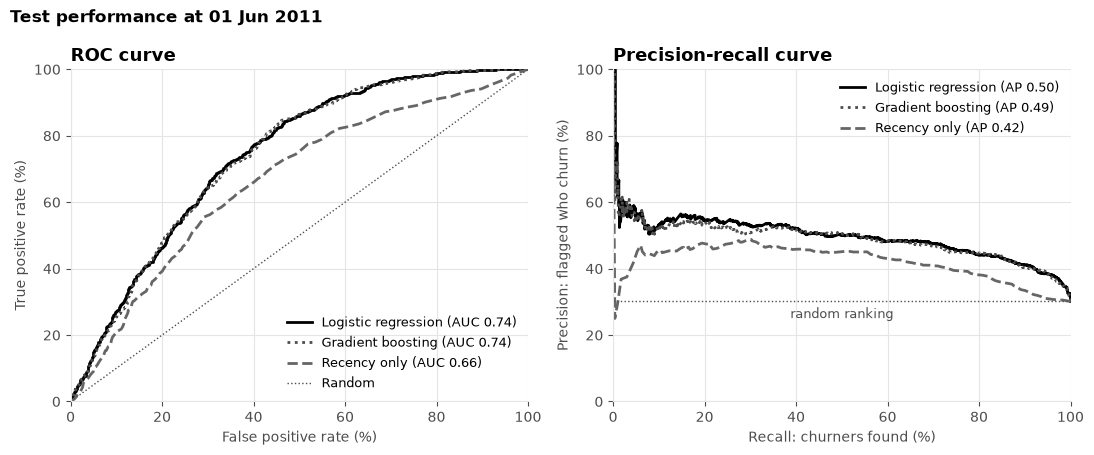

In [10]:
STYLES = {"Logistic regression": ("-", INK), "Gradient boosting": (":", INK_SECONDARY), "Recency only": ("--", NEUTRAL)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for name, p in predictions.items():
    style, color = STYLES[name]
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr * 100, tpr * 100, style, color=color, label=f"{name} (AUC {roc_auc_score(y_test, p):.2f})")
    precision, recall, _ = precision_recall_curve(y_test, p)
    axes[1].plot(recall * 100, precision * 100, style, color=color, label=f"{name} (AP {average_precision_score(y_test, p):.2f})")
axes[0].plot([0, 100], [0, 100], color=INK_SECONDARY, linestyle=":", linewidth=1, label="Random")
axes[1].axhline(y_test.mean() * 100, color=INK_SECONDARY, linestyle=":", linewidth=1)
axes[1].annotate("random ranking", (50, y_test.mean() * 100), xytext=(0, -12), textcoords="offset points", ha="center",
                 fontsize=9, color=INK_SECONDARY)
axes[0].set(xlabel="False positive rate (%)", ylabel="True positive rate (%)", title="ROC curve", xlim=(0, 100), ylim=(0, 100))
axes[1].set(xlabel="Recall: churners found (%)", ylabel="Precision: flagged who churn (%)", title="Precision-recall curve",
            xlim=(0, 100), ylim=(0, 100))
for ax in axes:
    ax.title.set_fontsize(11)
    ax.legend(loc="lower right" if ax is axes[0] else "upper right", fontsize=9)
    ax.grid(axis="x")
fig.suptitle(f"Test performance at {TEST_CUTOFF:%d %b %Y}", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "04_roc_pr_test")
plt.show()

**Findings: test performance**

- **The model ranks customers clearly better than recency alone.** Both ROC-AUC and PR-AUC improve, and the paired confidence intervals of the differences exclude zero.
- **The test scores are close to the out-of-fold scores of the June 2010 cutoff** (same season, similar churn rate), so there is no sign of overfitting. The out-of-fold figure is a little optimistic, because the folds share calendar periods.
- **Discrimination is moderate.** Whether a customer buys within a fixed 6-month window is noisy, partly because of seasonal and yearly buyers.

### 4.1 Are the probabilities calibrated?

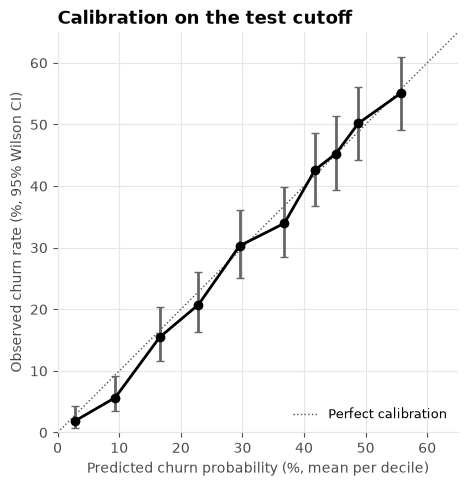

bin,predicted,observed,churners,customers
i64,f64,f64,i64,u32
0,2.8,1.9,5,265
1,9.3,5.7,15,265
2,16.6,15.5,41,265
3,22.9,20.8,55,265
4,29.5,30.3,80,264
5,36.8,34.0,90,265
6,41.8,42.6,113,265
7,45.2,45.3,120,265
8,48.8,50.2,133,265


In [11]:
p_test = predictions["Logistic regression"]
bins = np.quantile(p_test, np.linspace(0, 1, 11))
bin_id = np.clip(np.digitize(p_test, bins[1:-1]), 0, 9)
calibration = pl.DataFrame({"bin": bin_id, "predicted": p_test, "observed": y_test}).group_by("bin").agg(
    predicted=pl.col("predicted").mean() * 100, observed=pl.col("observed").mean() * 100,
    churners=pl.col("observed").sum(), customers=pl.len()
).sort("bin")
ci_low, ci_high = proportion_confint(calibration["churners"].to_numpy(), calibration["customers"].to_numpy(), method="wilson")

fig, ax = plt.subplots(figsize=(5.5, 5.2))
ax.plot([0, 65], [0, 65], color=INK_SECONDARY, linestyle=":", linewidth=1, label="Perfect calibration")
ax.errorbar(calibration["predicted"], calibration["observed"],
            yerr=[calibration["observed"] - ci_low * 100, ci_high * 100 - calibration["observed"]],
            marker="o", markersize=6, color=INK, ecolor=NEUTRAL, capsize=3)
ax.set(xlim=(0, 65), ylim=(0, 65), xlabel="Predicted churn probability (%, mean per decile)",
       ylabel="Observed churn rate (%, 95% Wilson CI)", title="Calibration on the test cutoff")
ax.set_aspect("equal")
ax.title.set_fontsize(11)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x")
save_fig(fig, "04_calibration")
plt.show()
calibration.with_columns(pl.col("predicted", "observed").round(1))

### 4.2 Whom should the retention team contact?

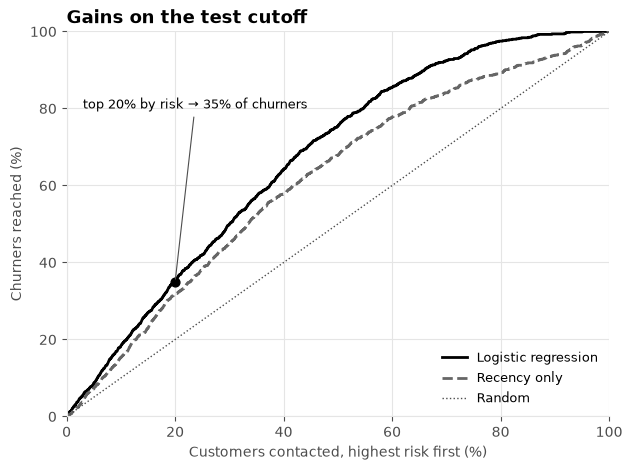

contact_top_pct,precision_pct,recall_pct,lift
f64,f64,f64,f64
10.0,54.9,18.2,1.8
20.0,52.7,35.0,1.8
30.0,50.1,49.9,1.7


In [12]:
def gains(scores_):
    order = np.argsort(-scores_)
    captured = np.cumsum(y_test[order]) / y_test.sum() * 100
    contacted = np.arange(1, len(y_test) + 1) / len(y_test) * 100
    return contacted, captured


fig, ax = plt.subplots(figsize=(7, 5))
for name in ["Logistic regression", "Recency only"]:
    style, color = STYLES[name]
    contacted, captured = gains(predictions[name])
    ax.plot(contacted, captured, style, color=color, label=name)
ax.plot([0, 100], [0, 100], color=INK_SECONDARY, linestyle=":", linewidth=1, label="Random")
contacted, captured = gains(predictions["Logistic regression"])
top20 = captured[int(0.2 * len(captured)) - 1]
ax.scatter([20], [top20], s=40, color=INK, zorder=3)
ax.annotate(f"top 20% by risk → {top20:.0f}% of churners", (20, top20), xytext=(3, 80), textcoords="data",
            fontsize=9, color=INK, arrowprops={"arrowstyle": "-", "color": INK_SECONDARY, "linewidth": 0.8})
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="Customers contacted, highest risk first (%)",
       ylabel="Churners reached (%)", title="Gains on the test cutoff")
ax.title.set_fontsize(11)
ax.legend(loc="lower right", fontsize=9)
ax.grid(axis="x")
save_fig(fig, "04_gains")
plt.show()

rows = []
for share in (0.1, 0.2, 0.3):
    k = int(share * len(y_test))
    top = np.argsort(-p_test)[:k]
    rows.append({"contact_top_pct": share * 100, "precision_pct": y_test[top].mean() * 100,
                 "recall_pct": y_test[top].sum() / y_test.sum() * 100, "lift": y_test[top].mean() / y_test.mean()})
pl.DataFrame(rows).with_columns(pl.exclude("contact_top_pct").round(1))

**Ranking by risk × value.** A retention budget is usually worth more on valuable customers. As a proxy for what a lapse costs, the value of a customer is taken to be their sales in the last 6 months. This is an assumption: it overstates the loss when those 6 months contained the autumn peak. The table compares, on the test cutoff, the share of churners' value reached by contacting the top k% ranked by risk alone or by risk × value.

In [13]:
sales_test = test["sales"].to_numpy()
lost_value = sales_test * y_test
rows = []
for share in (0.1, 0.2, 0.3):
    k = int(share * len(y_test))
    row = {"contact_top_pct": share * 100}
    for name, ranking in [("risk", p_test), ("value", sales_test), ("risk_x_value", p_test * sales_test)]:
        top = np.argsort(-ranking)[:k]
        row[f"churners_reached_pct_by_{name}"] = y_test[top].sum() / y_test.sum() * 100
        row[f"churner_value_reached_pct_by_{name}"] = lost_value[top].sum() / lost_value.sum() * 100
    rows.append(row)
print(pl.DataFrame(rows).select("contact_top_pct", pl.col("^churner_value_reached.*$"), pl.col("^churners_reached.*$"))
      .with_columns(pl.exclude("contact_top_pct").round(1)))
top1 = np.sort(lost_value[y_test == 1])[::-1]
print(f"The top 1% of churners hold {top1[: max(1, len(top1) // 100)].sum() / top1.sum():.0%} of churners' value: "
      "the value metric depends on a handful of customers")

shape: (3, 7)
┌─────────────────┬──────────────────────────────┬─────────────────────────────┬─────────────────────────────┬─────────────────────────────┬─────────────────────────────┬─────────────────────────────┐
│ contact_top_pct ┆ churner_value_reached_pct_by ┆ churner_value_reached_pct_b ┆ churner_value_reached_pct_b ┆ churners_reached_pct_by_ris ┆ churners_reached_pct_by_val ┆ churners_reached_pct_by_ris │
│ ---             ┆ _r…                          ┆ y_v…                        ┆ y_r…                        ┆ k                           ┆ ue                          ┆ k_x…                        │
│ f64             ┆ ---                          ┆ ---                         ┆ ---                         ┆ ---                         ┆ ---                         ┆ ---                         │
│                 ┆ f64                          ┆ f64                         ┆ f64                         ┆ f64                         ┆ f64                         ┆ f64        

**Findings: calibration and use**

- **At the June test cutoff, the probabilities are well calibrated.** Predicted and observed rates match within the confidence intervals in every decile except the second-lowest, where the risk is overestimated (about 9% predicted against 6% observed).
- **Ranking by risk alone:** contacting the top 20% reaches about a third of the churners, and about half of the contacted customers lapse, against 3 in 10 at random.
- **Ranking by risk × value:** contacting the top 20% reaches about half of the value that the churners represent. Ranking by risk alone reaches about a tenth, and by value alone about a third, so the risk score adds to value. It reaches fewer churners, though, and the value metric depends on a handful of very large customers.
- **How many customers to contact is the team's choice.** The tables show the top 10, 20 and 30% as examples. The right cut depends on how many customers the team can contact per month and what a contact costs, which this project does not know.
- **The choice depends on the goal.** Use risk alone to win back as many customers as possible, and risk × value to protect revenue. The value proxy (last 6 months of sales) is an assumption.

### 4.3 Does it matter that some customers appear at every cutoff?

A customer who is active at all 7 training cutoffs contributes 7 rows, so these customers weigh more in the fit than customers who appear once. The next cell refits the model giving each customer the same total weight, and compares the coefficients and the test scores.

In [14]:
rows_per_customer = train.group_by("customer_id").len()
share_always = rows_per_customer.filter(pl.col("len") == len(TRAIN_CUTOFFS))["len"].sum() / train.height
print(f"Rows from customers present at all {len(TRAIN_CUTOFFS)} cutoffs: {share_always:.0%}")

customer_weight = train.with_columns(w=1 / pl.len().over("customer_id"))["w"].to_numpy()
weighted = make_logreg().fit(X_train, y_train, logisticregression__sample_weight=customer_weight)

coef_names = LOG_FEATURES + OTHER_FEATURES  # order of the ColumnTransformer output
p_weighted = weighted.predict_proba(test.select(FEATURES))[:, 1]
print(pl.DataFrame({
    "feature": coef_names,
    "coef_every_row_equal": model[-1].coef_[0],
    "coef_every_customer_equal": weighted[-1].coef_[0],
}).with_columns(pl.exclude("feature").round(2)))
print(pl.DataFrame({
    "fit": ["every row equal", "every customer equal"],
    "test_roc_auc": [roc_auc_score(y_test, p_test), roc_auc_score(y_test, p_weighted)],
    "test_pr_auc": [average_precision_score(y_test, p_test), average_precision_score(y_test, p_weighted)],
}).with_columns(pl.exclude("fit").round(3)))

Rows from customers present at all 7 cutoffs: 54%
shape: (8, 3)
┌─────────────────┬──────────────────────┬───────────────────────────┐
│ feature         ┆ coef_every_row_equal ┆ coef_every_customer_equal │
│ ---             ┆ ---                  ┆ ---                       │
│ str             ┆ f64                  ┆ f64                       │
╞═════════════════╪══════════════════════╪═══════════════════════════╡
│ recency_days    ┆ 0.12                 ┆ 0.23                      │
│ orders          ┆ -0.24                ┆ -0.34                     │
│ avg_order_value ┆ -0.18                ┆ -0.15                     │
│ products        ┆ -0.17                ┆ -0.14                     │
│ active_months   ┆ -0.75                ┆ -0.75                     │
│ cancelled_share ┆ -0.01                ┆ -0.01                     │
│ is_uk           ┆ -0.0                 ┆ 0.02                      │
│ peak_days_ahead ┆ -0.37                ┆ -0.3                      │
└────────────

**Findings: weighting by customer**

- **The test scores hardly change** when each customer counts once instead of once per cutoff, so the model is not tuned to the customers who appear at every cutoff.
- **The pattern of the coefficients is the same:** `active_months` stays the largest and every sign is unchanged. Recency and orders get somewhat larger in size, which is another reason not to rank the individual activity coefficients.

## 5. What drives the risk?

These are the standardised coefficients of the logistic regression: the change in log-odds of churn per one standard deviation of each (log-transformed) feature, holding the others fixed. **These are associations, not causes.** Two cautions apply:
- Orders, active months and products are strongly correlated, so their individual coefficients share the same information and should not be ranked. The drop-one-feature table below measures what each feature adds.
- Customers are resampled 200 times for the intervals, because the same customer appears at several cutoffs. That says nothing about `peak_days_ahead`, which is one value per cutoff (7 in training). Its coefficient is shown without an interval.

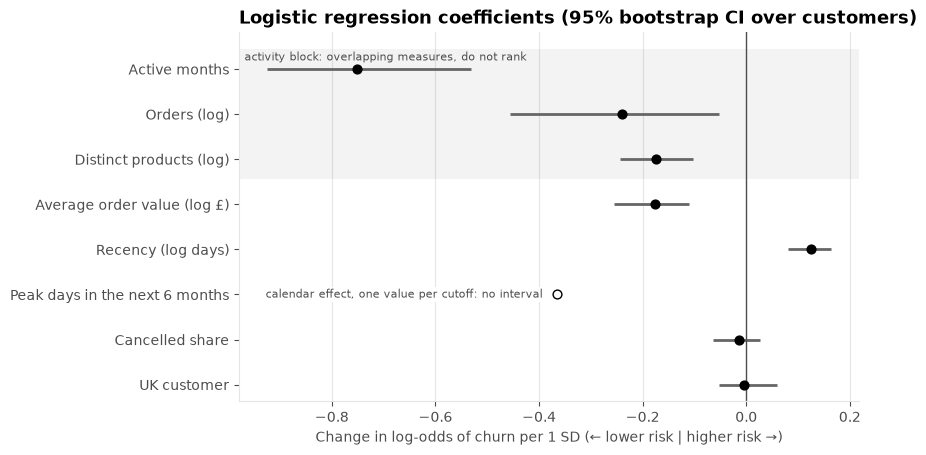

feature,coefficient,ci_low,ci_high
str,f64,f64,f64
"""active_months""",-0.75,-0.92,-0.53
"""peak_days_ahead""",-0.37,NaN,NaN
"""orders""",-0.24,-0.46,-0.05
"""avg_order_value""",-0.18,-0.25,-0.11
"""products""",-0.17,-0.24,-0.1
"""recency_days""",0.12,0.08,0.16
"""cancelled_share""",-0.01,-0.06,0.03
"""is_uk""",-0.0,-0.05,0.06


In [15]:
LABELS = {
    "recency_days": "Recency (log days)", "orders": "Orders (log)",
    "avg_order_value": "Average order value (log £)", "products": "Distinct products (log)",
    "active_months": "Active months", "cancelled_share": "Cancelled share", "is_uk": "UK customer",
    "peak_days_ahead": "Peak days in the next 6 months",
}
names = LOG_FEATURES + OTHER_FEATURES  # order of the ColumnTransformer output
coef = model[-1].coef_[0]

customer_ids = train["customer_id"].unique().to_numpy()
boot_coef = []
for _ in range(200):
    drawn = pl.DataFrame({"customer_id": rng.choice(customer_ids, size=len(customer_ids), replace=True)})
    sample = drawn.join(train, on="customer_id")
    boot_coef.append(make_logreg().fit(sample.select(FEATURES), sample["churned"].to_numpy())[-1].coef_[0])
low, high = np.percentile(boot_coef, [2.5, 97.5], axis=0)

calendar = names.index("peak_days_ahead")
low[calendar] = high[calendar] = np.nan  # not estimable by resampling customers
GROUP_ORDER = ["active_months", "orders", "products", "avg_order_value", "recency_days", "peak_days_ahead",
               "cancelled_share", "is_uk"]  # activity block first, as a group: not a ranking
order = np.array([names.index(f) for f in GROUP_ORDER])[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.hlines(range(len(order)), low[order], high[order], color=NEUTRAL, linewidth=2)
is_calendar = order == calendar
ax.scatter(coef[order][~is_calendar], np.arange(len(order))[~is_calendar], color=INK, s=40, zorder=3)
row = int(np.flatnonzero(is_calendar)[0])
ax.scatter([coef[calendar]], [row], s=40, facecolors="white", edgecolors=INK, zorder=3)
ax.annotate("calendar effect, one value per cutoff: no interval", (coef[calendar], row), xytext=(-10, 0),
            textcoords="offset points", ha="right", fontsize=8, color=INK_SECONDARY, va="center",
            bbox={"fc": "white", "ec": "none", "pad": 1})
activity_rows = [len(order) - 1 - i for i in range(3)]
ax.axhspan(min(activity_rows) - 0.45, max(activity_rows) + 0.45, color=NEUTRAL, alpha=0.08, linewidth=0)
ax.annotate("activity block: overlapping measures, do not rank", (ax.get_xlim()[0], max(activity_rows) + 0.45),
            xytext=(4, -2), textcoords="offset points", fontsize=8, color=INK_SECONDARY, va="top")
ax.axvline(0, color=INK_SECONDARY, linewidth=1)
ax.set_yticks(range(len(order)), [LABELS[names[i]] for i in order])
ax.set_xlabel("Change in log-odds of churn per 1 SD (← lower risk | higher risk →)")
ax.set_title("Logistic regression coefficients (95% bootstrap CI over customers)")
ax.title.set_fontsize(11)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
save_fig(fig, "04_coefficients")
plt.show()

pl.DataFrame({"feature": names, "coefficient": coef, "ci_low": low, "ci_high": high}).with_columns(
    pl.exclude("feature").round(2)
).sort(pl.col("coefficient").abs(), descending=True)

In [16]:
# What each feature adds: refit without it and score the test cutoff; also each feature on its own
full_auc = roc_auc_score(y_test, p_test)
rows = []
for feature in FEATURES:
    kept = [f for f in FEATURES if f != feature]
    reduced = make_logreg(kept).fit(train.select(kept), y_train)
    alone = test[feature].to_numpy().astype(float)
    alone_auc = roc_auc_score(y_test, alone)
    rows.append({"feature": feature,
                 "auc_drop_without_it": full_auc - roc_auc_score(y_test, reduced.predict_proba(test.select(kept))[:, 1]),
                 "auc_on_its_own": max(alone_auc, 1 - alone_auc)})
print(f"Test ROC-AUC with all features: {full_auc:.3f}")
pl.DataFrame(rows).with_columns(pl.exclude("feature").round(3)).sort("auc_drop_without_it", descending=True)

Test ROC-AUC with all features: 0.742


feature,auc_drop_without_it,auc_on_its_own
str,f64,f64
"""products""",0.005,0.688
"""active_months""",0.005,0.706
"""recency_days""",0.004,0.663
"""avg_order_value""",0.001,0.599
"""peak_days_ahead""",0.001,0.5
"""orders""",-0.0,0.705
"""cancelled_share""",0.0,0.563
"""is_uk""",0.0,0.502


`peak_days_ahead` takes a single value at the test cutoff, so it cannot change the test ranking. Its row in this table says nothing about its contribution, which is to set the level by season.

**Findings: risk drivers**

- **The protective signal is one block of activity:** buying in several months, placing more orders and buying more distinct products. These measures overlap so much that none of them adds much once the others are in the model, so they should not be ranked against each other.
- Recency raises the risk. On its own it ranks customers less well than the activity measures, and it adds little to them.
- Larger orders go with a slightly lower risk.
- The calendar shifts the risk for everyone: label windows that include the autumn peak have fewer lapses.
- Unmatched cancellations (`cancelled_share`) and country show no detectable effect.
- These are associations: they say who to watch, not what will make a customer stay.

## 6. Today's customers: who is at risk?

The final model is refitted on all 13 cutoffs whose label window is fully observed (June 2010 to June 2011). It then scores the customers who bought in the 6 months up to 1 December 2011. That is the last first-of-month cutoff, like the training cutoffs, and the last 8 days of data are not used.

**Read today's scores mainly as a ranking.** Calibration was only tested at a June cutoff. Today's label window (December 2011 to May 2012) has no autumn days. The model learned that winter level from the 2010–11 winter cutoffs, but it was never tested on later data, and the seasonal term rests on only 13 cutoffs in one year.

The score is joined to the segments from `02`. Those segments are built on recency and value too, so they partly repeat what the model sees, but over 2 years of history instead of 6 months. The segments use data up to 9 December 2011, 8 days after the scoring cutoff. They only describe the customers and are not a model feature, so there is no leakage. Customers who have not bought in the last 6 months (most of "Lost") are not scored: by the label definition they are already churned.

In [17]:
labelled = pl.concat([datasets[c] for c in LABELLED_CUTOFFS])
final_model = make_logreg().fit(labelled.select(FEATURES), labelled["churned"].to_numpy())

current = churn_features(lines, SCORE_CUTOFF)
segments = pl.read_parquet(SEGMENTS).select("customer_id", "segment")
scored = current.with_columns(churn_probability=final_model.predict_proba(current.select(FEATURES))[:, 1]).join(
    segments, on="customer_id", how="left"
).with_columns(
    pl.col("segment").fill_null("Not segmented"),
    risk_decile=(pl.col("churn_probability").rank(method="ordinal", descending=True) * 10 / pl.len()).ceil().cast(pl.Int8),
    expected_sales_at_risk=pl.col("churn_probability") * pl.col("sales"),
)
print(f"Customers scored at {SCORE_CUTOFF}: {scored.height:,} | mean churn probability {scored['churn_probability'].mean():.1%}")

by_segment = (
    scored.group_by("segment")
    .agg(
        customers=pl.len(),
        median_churn_probability=pl.col("churn_probability").median() * 100,
        sales_last_6m=pl.col("sales").sum(),
        expected_sales_at_risk=pl.col("expected_sales_at_risk").sum(),
    )
    .with_columns(pct_of_sales_at_risk=pl.col("expected_sales_at_risk") / pl.col("expected_sales_at_risk").sum() * 100)
    .sort(pl.col("segment").replace_strict({s: i for i, s in enumerate(SEGMENT_ORDER + ["Not segmented"])}))
    .with_columns(pl.selectors.float().round(0))
)
print(f"Champions in the two highest risk deciles: {scored.filter(pl.col('segment') == 'Champions', pl.col('risk_decile') <= 2).height}")
by_segment

Customers scored at 2011-12-01: 3,444 | mean churn probability 44.1%
Champions in the two highest risk deciles: 15


segment,customers,median_churn_probability,sales_last_6m,expected_sales_at_risk,pct_of_sales_at_risk
str,u32,f64,f64,f64,f64
"""Champions""",1083,18.0,3.534526e6,306105.0,34.0
"""Promising""",1273,57.0,623790.0,266872.0,30.0
"""At risk""",844,59.0,607967.0,263317.0,30.0
"""Lost""",240,70.0,99086.0,53803.0,6.0
"""Not segmented""",4,83.0,378.0,231.0,0.0


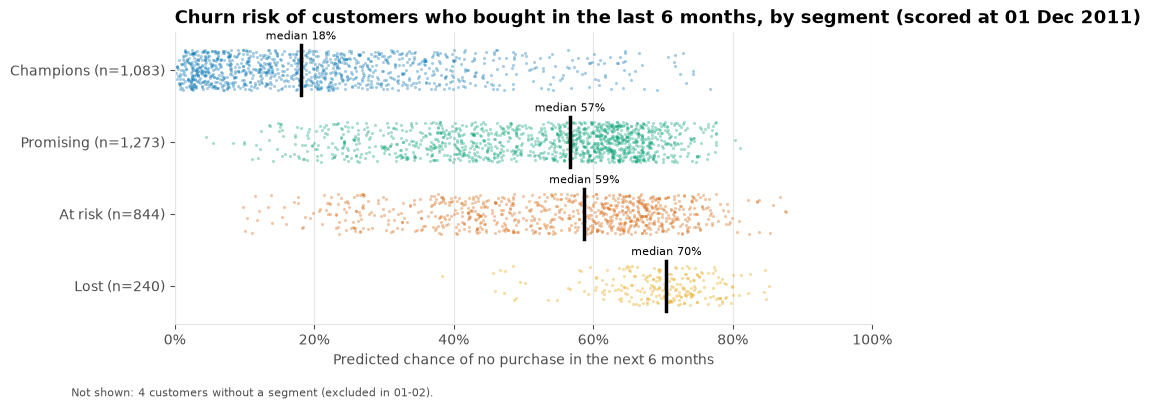

In [18]:
shown = [s for s in SEGMENT_ORDER if scored.filter(pl.col("segment") == s).height >= 20]
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, segment in enumerate(shown):
    values = scored.filter(pl.col("segment") == segment)["churn_probability"].to_numpy() * 100
    ax.scatter(values, i + rng.uniform(-0.28, 0.28, len(values)), s=5, alpha=0.35, color=SEGMENT_COLORS[segment],
               linewidths=0, rasterized=True)
    median = np.median(values)
    ax.plot([median, median], [i - 0.35, i + 0.35], color=INK, linewidth=2.5)
    ax.annotate(f"median {median:.0f}%", (median, i - 0.35), xytext=(0, 2), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, color=INK)
ax.set_yticks(range(len(shown)), [f"{s} (n={scored.filter(pl.col('segment') == s).height:,})" for s in shown])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("Predicted chance of no purchase in the next 6 months")
ax.set_title(f"Churn risk of customers who bought in the last 6 months, by segment (scored at {SCORE_CUTOFF:%d %b %Y})")
dropped = scored.filter(~pl.col("segment").is_in(shown)).height
if dropped:
    fig.text(0.01, -0.08, f"Not shown: {dropped} customers without a segment (excluded in 01-02).", fontsize=8,
             color=INK_SECONDARY)
ax.title.set_fontsize(11)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
save_fig(fig, "04_risk_by_segment")
plt.show()

In [19]:
scored.select("customer_id", "segment", "churn_probability", "risk_decile", "sales", "recency_days",
              "orders", "expected_sales_at_risk").sort("churn_probability", descending=True).write_parquet(CHURN_SCORES)
print(f"Saved {scored.height:,} scored customers to {CHURN_SCORES.name}")

Saved 3,444 scored customers to churn_scores.parquet


**Findings: today's customers**

- **Use today's scores mainly as a ranking.** The mean predicted risk is much higher than on the test cutoff, because the next 6 months contain no autumn peak, but that seasonal level was never tested on later data.
- **Champions have a low risk,** about 1 in 5 at the median. They spend so much that they still hold about a third of the expected sales at risk, so the small group of Champions in the two highest risk deciles (15 customers) is worth a personal contact.
- **Promising and At risk customers have a median risk of around 55–60%.** Together they hold most of the expected sales at risk, so they are the main targets of a retention campaign.
- **Read the expected sales at risk as relative sizes, not as amounts.** The value proxy is the sales of the last 6 months, and for today's cutoff that window contains the autumn peak, so the amounts are overstated.
- `data/processed/churn_scores.parquet` has the probability, the risk decile and the expected sales at risk for each scored customer.

## Summary

- **Model:** a logistic regression on eight features from the last 6 months, evaluated by training on the 2010 cutoffs and testing once on June 2011. It beats a recency-only ranking, gradient boosting does not beat it, and its probabilities are well calibrated at the test cutoff. The model that scores today's customers is refitted on all 13 labelled cutoffs, up to June 2011.
- **Label caveat:** with a 6-month window, a quarter to a third of the "churned" customers buy again in the following 6 months. The model predicts lapses, not permanent losses.
- **Drivers:** a block of activity (buying in several months, more orders, more distinct products) goes with lower risk, and the calendar shifts the risk for everyone. The individual activity measures overlap and should not be ranked.
- **Use:**
  - Rank today's customers by risk × value to protect revenue, or by risk alone to maximise the number of customers kept.
  - Give high-risk Champions a personal contact.
  - Target Promising customers with a second-order offer and At risk customers with reactivation. The timing is a suggestion: nothing here tests it.
  - Measure any campaign against a random hold-out group, because the model predicts who will lapse, not what will make them stay.
- **Limitations:**
  - There is a single test cutoff (June), so calibration in winter is untested.
  - The training data comes from one year (2010).
  - The features cover only 6 months of history.
  - The `02` segments partly repeat what the model sees: they use the same kind of information (recency and value) over 2 years.